# 12. Phase separation

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 3–5

Cool a mixture of two polymers, or of oil and a surfactant solution, below its
critical temperature, and it separates into two phases. If it is quenched deep
enough, it does not wait for droplets of the new phase to nucleate: tiny
fluctuations of composition grow everywhere at once, with a preferred wavelength,
into an interwoven pattern of the two phases. This is *spinodal decomposition*.
The pattern then coarsens: small domains dissolve and large ones grow, for as
long as one waits.

The equation that describes all of this, the Cahn–Hilliard equation, is a
textbook case of the Onsager principle. The free energy is that of a mixture
with a penalty for gradients of composition; the dissipation is the friction of
interdiffusion. This chapter derives the equation from the Rayleighian, finds the
phase diagram, the interface and the growth rate of fluctuations, and then uses
trial functions made of a few Fourier modes to follow the growth of the pattern
until it saturates. A scaling argument with the same two functions gives the law
of coarsening, $\ell \propto t^{1/3}$, which we compare with a simulation in two dimensions.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

def f(p, chi):
    """Flory-Huggins free energy of a symmetric blend, in units of kT/(vN)."""
    return p * np.log(p) + (1 - p) * np.log(1 - p) + chi * p * (1 - p)

def df(p, chi):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return np.log(p / (1 - p)) + chi * (1 - 2 * p)

def d2f(p, chi):
    return 1 / (p * (1 - p)) - 2 * chi

def binodal(chi):
    """Composition of the poorer phase; the other is 1 - binodal(chi)."""
    return brentq(lambda p: df(p, chi), 1e-12, 0.5 - 1e-9)

## 12.1 The two functions of a mixture

A mixture of two species A and B fills the space; $\phi(\mathbf r,t)$ is the volume
fraction of A, and $1 - \phi$ that of B.

*Free energy.* Following Cahn and Hilliard (1958), the free energy of a mixture
whose composition varies in space is

$$ A = \int\Big[f(\phi) + \frac{\kappa}{2}\,|\nabla\phi|^2\Big]\,dV . \tag{12.1} $$

The first term is the free energy of mixing of a uniform mixture. The second is
the cost of a gradient: neighbouring regions of different composition have
unfavourable contacts across the boundary between them, and the cost grows with
the gradient. For a blend of two polymers with $N$ segments each and segment volume
$v$, the free energy of mixing is that of Flory and Huggins,

$$ f(\phi) = \frac{k_BT}{vN}\Big[\phi\ln\phi + (1 - \phi)\ln(1 - \phi) + \chi N\,\phi(1 - \phi)\Big] , \tag{12.2} $$

with the interaction parameter $\chi$. For $N = 1$ it is the regular solution of small
molecules. (Chapter 3 computed the functional derivative of this free energy.)

*Dissipation.* The two species move relative to each other. With the flux $\mathbf j$
of A relative to the mixture, conservation gives $\partial\phi/\partial t = -\nabla\cdot\mathbf j$,
and the friction of interdiffusion is

$$ \Phi = \int\frac{\mathbf j^2}{2\Lambda}\,dV , \tag{12.3} $$

where $\Lambda$ is the Onsager coefficient of interdiffusion, a mobility (Chapter 4).

*Minimise.* As in Chapter 4, $\dot A = \int\mu\,\partial_t\phi\,dV = \int\mathbf j\cdot\nabla\mu\,dV$, where
$\mu = \delta A/\delta\phi$ is the exchange chemical potential. Minimising $R = \Phi + \dot A$ over $\mathbf j$
gives $\mathbf j = -\Lambda\nabla\mu$ and the *Cahn–Hilliard equation*

$$ \frac{\partial\phi}{\partial t} = \nabla\cdot\big(\Lambda\,\nabla\mu\big) , \qquad \mu = f'(\phi) - \kappa\,\nabla^2\phi . \tag{12.4} $$

The cell below does the two steps with sympy.

*Units.* We take $\kappa$ and $\Lambda$ constant, measure energies per volume in units of
$k_BT/vN$, lengths in units of $\ell_0 = (\kappa vN/k_BT)^{1/2}$ and times in units of $\ell_0^2vN/\Lambda k_BT$.
Then

$$ \frac{\partial\phi}{\partial t} = \nabla^2\big(f'(\phi) - \nabla^2\phi\big) , \tag{12.5} $$

with $f$ the bracket of Eq. (12.2). The only parameter left is $\chi N$, and the mean
composition $\bar\phi$. The function `on.cahn_hilliard_spectral` solves Eq. (12.5) on a
periodic interval or square.

In [2]:
x = sp.symbols("x")
phi = sp.Function("phi")(x)
fs, kappa = sp.Function("f"), sp.symbols("kappa", positive=True)
density = fs(phi) + kappa / 2 * sp.diff(phi, x) ** 2
mu = sp.euler_equations(density, [phi], [x])[0].lhs          # delta A / delta phi
print("mu =", sp.simplify(mu))

j, dmu = sp.symbols("j dmu", real=True)
Lam = sp.symbols("Lambda", positive=True)
R = j**2 / (2 * Lam) + j * dmu                                # Rayleighian density; dmu = d(mu)/dx
print("j  =", sp.solve(sp.diff(R, j), j)[0])

mu = -kappa*Derivative(phi(x), (x, 2)) + Derivative(f(phi(x)), phi(x))
j  = -Lambda*dmu


## 12.2 Equilibrium: the phase diagram and the interface

A uniform mixture is unstable to small changes of composition where $f'' < 0$. The
boundary is the *spinodal*, and for the symmetric blend

$$ \chi N = \frac{1}{2\phi(1 - \phi)} . \tag{12.6} $$

Its minimum, $\chi N = 2$ at $\phi = \tfrac12$, is the critical point. Between the spinodal and the
*binodal* the mixture is metastable. Two coexisting phases have equal exchange
chemical potentials and equal osmotic pressures; for the symmetric blend they are
$\phi_e$ and $1 - \phi_e$, with $f'(\phi_e) = 0$, which gives

$$ \chi N = \frac{1}{1 - 2\phi_e}\,\ln\frac{1 - \phi_e}{\phi_e} . \tag{12.7} $$

*The interface.* Between the two phases the composition changes over a finite
width. In a flat interface the chemical potential is uniform, $\mu = 0$; multiplying
$f'(\phi) - \kappa\phi'' = 0$ by $\phi'$ and integrating once gives
$\tfrac12\kappa\phi'^2 = \Delta f(\phi) \equiv f(\phi) - f(\phi_e)$: in the interface the gradient
energy equals the excess free energy of mixing. The excess free energy per unit
area, the interfacial tension, follows without solving for the profile:

$$ \gamma = \int\big[\Delta f + \tfrac12\kappa\phi'^2\big]\,dz = \int_{\phi_e}^{1 - \phi_e}\sqrt{2\kappa\,\Delta f(\phi)}\;d\phi . \tag{12.8} $$

The profile itself is $z(\phi) = \int d\phi/\sqrt{2\Delta f/\kappa}$.

In [3]:
print("  chi N    binodal phi_e    tension gamma (Eq. 12.8)    numerical (two interfaces, 1D)")
tension = {}
# relaxation time and step: near the critical point the interfaces are wide and relax slowly
relax = {2.2: (4000.0, 0.05), 2.5: (400.0, 0.01), 3.0: (400.0, 0.01)}
for chi in (2.2, 2.5, 3.0):
    pe = binodal(chi)
    gamma = quad(lambda p: math.sqrt(max(2 * (f(p, chi) - f(pe, chi)), 0.0)), pe, 1 - pe, limit=200)[0]
    n, box = 1024, 200.0
    xx = np.arange(n) * box / n
    relaxed = on.cahn_hilliard_spectral(np.where((xx > 50) & (xx < 150), 1 - pe, pe), box, [0.0, relax[chi][0]],
                                        lambda p, c=chi: df(p, c), relax[chi][1])[-1]
    k = 2 * np.pi * np.fft.fftfreq(n, d=box / n)
    grad = np.real(np.fft.ifft(1j * k * np.fft.fft(relaxed)))
    excess = np.sum(f(relaxed, chi) - f(pe, chi) + 0.5 * grad**2) * (box / n) / 2
    tension[chi] = (pe, gamma, xx, relaxed)
    print(f"   {chi:3.1f}      {pe:.5f}           {gamma:.6f}                  {excess:.6f}")

  chi N    binodal phi_e    tension gamma (Eq. 12.8)    numerical (two interfaces, 1D)


   2.2      0.24853           0.039227                  0.039227


   2.5      0.14479           0.130258                  0.130258


   3.0      0.07072           0.288272                  0.288272


## 12.3 Spinodal decomposition: the growth of fluctuations

Linearise Eq. (12.4) about a uniform composition $\bar\phi$ inside the spinodal. A small
change $\delta\phi \propto e^{i\mathbf q\cdot\mathbf r + \omega t}$ grows at the rate (Cahn, 1961)

$$ \omega(q) = -\Lambda q^2\big(f''(\bar\phi) + \kappa q^2\big) . \tag{12.9} $$

Long waves grow slowly, because material has to diffuse far; short waves are
stopped by the gradient energy. The fastest wave number and its rate are

$$ q_m^2 = -\frac{f''(\bar\phi)}{2\kappa} , \qquad \omega_m = \frac{\Lambda f''(\bar\phi)^2}{4\kappa} . \tag{12.10} $$

This is what light and neutron scattering see in the first stage of phase
separation of polymer blends: a ring of scattered intensity at $q_m$ that grows
exponentially without moving (de Gennes, 1980). The cell below starts from a
nearly uniform mixture with small random noise, follows the amplitudes of the
Fourier modes, and checks the energy balance $\dot A = -2\Phi$ of the full nonlinear
evolution.

In [4]:
rng = np.random.default_rng(0)
growth = {}
for chi in (2.2, 2.5, 3.0):
    n, box = 512, 400.0
    t_lin = np.linspace(0, 6 / (d2f(0.5, chi) ** 2 / 4), 13)
    t_lin = np.round(t_lin / 0.01) * 0.01
    snaps = on.cahn_hilliard_spectral(0.5 + 1e-7 * rng.standard_normal(n), box, t_lin, lambda p, c=chi: df(p, c), 0.01)
    amp = np.abs(np.fft.rfft(snaps, axis=1))
    k = 2 * np.pi * np.fft.rfftfreq(n, d=box / n)
    modes = np.arange(4, len(k), 6)
    modes = modes[k[modes] < 0.95 * math.sqrt(-d2f(0.5, chi))]
    rates = np.array([np.polyfit(t_lin[4:], np.log(amp[4:, m]), 1)[0] for m in modes])
    theory = -k[modes] ** 2 * (d2f(0.5, chi) + k[modes] ** 2)
    growth[chi] = (k[modes], rates)
    print(f"chi N = {chi}:  q_m = {math.sqrt(-d2f(0.5, chi) / 2):.3f},  omega_m = {d2f(0.5, chi) ** 2 / 4:.4f};"
          f"  {len(modes)} modes, largest relative difference from Eq. (12.9): {np.max(np.abs(rates / theory - 1)):.1e}")

# energy balance of a nonlinear run
chi, n, box, dt = 2.5, 512, 200.0, 0.01
k = 2 * np.pi * np.fft.fftfreq(n, d=box / n)
noise = np.fft.fft(rng.standard_normal(n)) * (np.abs(k) < 1.5)       # smooth noise: no grid-scale transient
start = 0.5 + 0.01 * np.real(np.fft.ifft(noise)) / np.std(np.real(np.fft.ifft(noise)))
t_e = np.arange(0, 400.001, 0.05)
snaps = on.cahn_hilliard_spectral(start, box, t_e, lambda p: df(p, chi), dt)
def deriv(u):
    return np.real(np.fft.ifft(1j * k * np.fft.fft(u)))
energy = np.array([np.mean(f(np.clip(s, 1e-12, 1 - 1e-12), chi) + 0.5 * deriv(s) ** 2) for s in snaps])
two_phi = np.array([np.mean(deriv(df(s, chi) - np.real(np.fft.ifft(-k**2 * np.fft.fft(s)))) ** 2) for s in snaps])
dissipated = np.concatenate(([0.0], np.cumsum(0.5 * (two_phi[1:] + two_phi[:-1]) * np.diff(t_e))))
print(f"\nenergy balance, chi N = 2.5: A(0) - A(400) = {energy[0] - energy[-1]:.6f},"
      f"  integral of 2 Phi = {dissipated[-1]:.6f}, largest mismatch along the way {np.max(np.abs(energy[0] - energy - dissipated)):.1e}")

chi N = 2.2:  q_m = 0.447,  omega_m = 0.0400;  6 modes, largest relative difference from Eq. (12.9): 2.2e-06
chi N = 2.5:  q_m = 0.707,  omega_m = 0.2500;  10 modes, largest relative difference from Eq. (12.9): 4.3e-05
chi N = 3.0:  q_m = 1.000,  omega_m = 1.0000;  14 modes, largest relative difference from Eq. (12.9): 4.4e-04



energy balance, chi N = 2.5: A(0) - A(400) = 0.016308,  integral of 2 Phi = 0.016308, largest mismatch along the way 7.6e-08


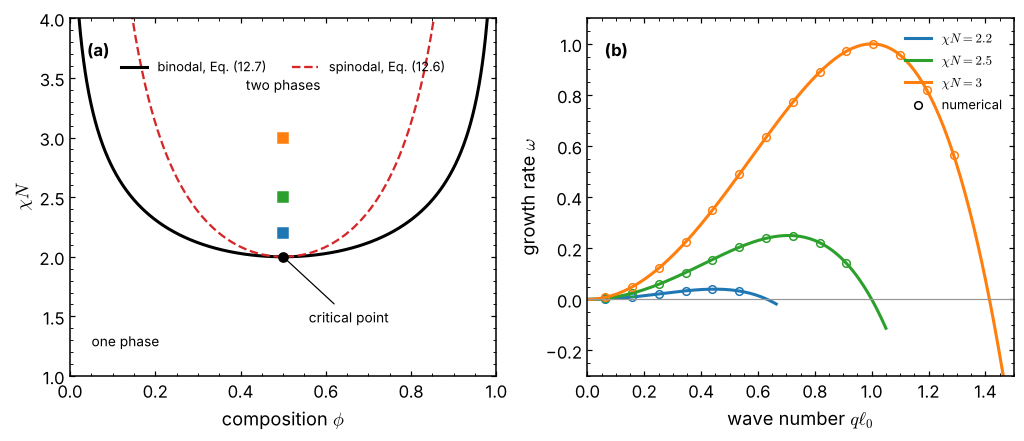

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
pp = np.linspace(0.005, 0.995, 400)
bin_p = np.linspace(0.0005, 0.4999, 400)
bin_chi = np.log((1 - bin_p) / bin_p) / (1 - 2 * bin_p)
ax1.plot(np.concatenate((bin_p, 1 - bin_p[::-1])), np.concatenate((bin_chi, bin_chi[::-1])), "k", lw=2, label="binodal, Eq. (12.7)")
ax1.plot(pp, 1 / (2 * pp * (1 - pp)), "C3--", lw=1.5, label="spinodal, Eq. (12.6)")
ax1.plot(0.5, 2, "ko", ms=6)
ax1.annotate("critical point", (0.5, 2), (0.56, 1.45), fontsize=9, arrowprops=dict(arrowstyle="-", lw=0.8))
for chi, color in zip((2.2, 2.5, 3.0), ("C0", "C2", "C1")):
    ax1.plot(0.5, chi, "s", color=color, ms=6)
ax1.text(0.5, 3.4, "two phases", ha="center", fontsize=9); ax1.text(0.13, 1.25, "one phase", ha="center", fontsize=9)
ax1.set_xlabel(r"composition $\phi$"); ax1.set_ylabel(r"$\chi N$"); ax1.set_xlim(0, 1); ax1.set_ylim(1, 4)
ax1.legend(loc="upper center", fontsize=8.5, ncol=2, bbox_to_anchor=(0.5, 0.92)); on.panel_label(ax1, "(a)", x=0.04, y=0.94)

for chi, color in zip((2.2, 2.5, 3.0), ("C0", "C2", "C1")):
    q = np.linspace(0, math.sqrt(-d2f(0.5, chi)) * 1.05, 200)
    ax2.plot(q, -q**2 * (d2f(0.5, chi) + q**2), color=color, lw=2, label=rf"$\chi N = {chi:g}$")
    qq, rr = growth[chi]
    ax2.plot(qq, rr, "o", color=color, mfc="none", ms=5)
ax2.plot([], [], "ko", mfc="none", ms=5, label="numerical")
ax2.axhline(0, color="0.6", lw=0.8)
ax2.set_xlabel(r"wave number $q\ell_0$"); ax2.set_ylabel(r"growth rate $\omega$"); ax2.set_xlim(0, 1.5); ax2.set_ylim(-0.3, 1.1)
ax2.legend(loc="upper right", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.04, y=0.94)
plt.show()

**Figure 12.1.** **(a)** Phase diagram of a symmetric blend: the binodal (full line)
and the spinodal (dashed), which meet at the critical point. The squares mark the
three quenches used in this chapter, all at $\phi = \tfrac12$. **(b)** Growth rate of small
fluctuations against their wave number, Eq. (12.9) (lines), and from the numerical
solution (circles).

The growth rates agree to better than $10^{-3}$, and the energy balance holds
along the whole nonlinear evolution, to the accuracy of the time steps.

## 12.4 Trial functions: from growth to saturation

The linear theory says that fluctuations grow exponentially; it cannot say when
they stop. The approximation method of Chapter 5 can. Take a box of one wavelength,
$2\pi/q$, at the critical composition $\bar\phi = \tfrac12$, and try a profile made of a few
Fourier modes,

$$ \phi = \tfrac12 + \sum_{m\ \mathrm{odd}}a_m(t)\cos(mqx) . \tag{12.11} $$

Only odd harmonics are needed: the symmetric mixture does not generate the even
ones. The flux that produces $\dot a_m$ is $j = -\sum\dot a_m\sin(mqx)/mq$, so the friction is
$\Phi = \tfrac14\sum\dot a_m^2/(mq)^2$ per unit length, and the free energy per unit length is
$\langle f(\phi)\rangle + \tfrac14\sum(mq)^2a_m^2$, where $\langle\cdot\rangle$ is the average over the box.
Minimising the Rayleighian gives

$$ \dot a_m = -2(mq)^2\Big[\big\langle f'(\phi)\cos(mqx)\big\rangle + \tfrac12(mq)^2a_m\Big] . \tag{12.12} $$

With one mode and small $a_1$ this is exactly Eq. (12.9): the trial contains the linear
theory. The nonlinear term stops the growth when the average of $f'(\phi)\cos qx$
balances the gradient term. With many modes, Eq. (12.12) is a spectral method for
Eq. (12.5), and it must converge to the numerical solution.

We test three cases: a shallow quench ($\chi N = 2.2$) and a deep one ($\chi N = 3$) in a box of
the fastest wavelength $2\pi/q_m$, and the deep quench in a box about three times
longer.

In [6]:
def trial(n_modes, chi, q, a0, times, nx=1024):
    """Odd-mode trial (12.11): returns the amplitudes a_m(t) and the profile on a grid."""
    xg = np.arange(nx) * 2 * np.pi / (q * nx)
    m = 2 * np.arange(n_modes) + 1
    C = np.cos(np.outer(m, q * xg))
    def rhs(t, a):
        return -2 * (m * q) ** 2 * (C @ df(0.5 + a @ C, chi) / nx + 0.5 * (m * q) ** 2 * a)
    def jac(t, a):
        p = np.clip(0.5 + a @ C, 1e-9, 1 - 1e-9)
        curv = (C * d2f(p, chi)) @ C.T / nx
        return -2 * ((m * q) ** 2)[:, None] * (curv + np.diag(0.5 * (m * q) ** 2))
    a_init = np.zeros(n_modes); a_init[0] = a0
    sol = solve_ivp(rhs, (0, times[-1]), a_init, t_eval=times, method="BDF", jac=jac, rtol=1e-9, atol=1e-12)
    return sol.y.T, xg, C

cases = {"shallow": (2.2, None, 250.0), "deep": (3.0, None, 40.0), "deep, long box": (3.0, 0.35, 400.0)}
results = {}
print("                   q      a_1 (numerical)   a_1 from the trial with 1, 2, 3, 5, 9 modes")
for name, (chi, q, t_end) in cases.items():
    q = math.sqrt(-d2f(0.5, chi) / 2) if q is None else q
    times = np.linspace(0, t_end, 101)
    nx = 512
    xg = np.arange(nx) * 2 * np.pi / (q * nx)
    numerical = on.cahn_hilliard_spectral(0.5 + 0.01 * np.cos(q * xg), 2 * np.pi / q, times, lambda p, c=chi: df(p, c), t_end / 20000)
    a1_num = 2 * np.real(np.fft.rfft(numerical, axis=1)[:, 1]) / nx
    runs = {}
    for n_modes in (1, 2, 3, 5, 9):
        a, xt, C = trial(n_modes, chi, q, 0.01, times, nx=nx)
        runs[n_modes] = (a, 0.5 + a @ C)
    results[name] = (chi, q, times, xg, numerical, a1_num, runs)
    print(f"{name:16s} {q:6.3f}     {a1_num[-1]:.4f}          " + "  ".join(f"{runs[n][0][-1, 0]:.4f}" for n in (1, 2, 3, 5, 9)))
print("\nlargest error of the final profile")
for name, (chi, q, times, xg, numerical, a1_num, runs) in results.items():
    print(f"{name:16s} " + "  ".join(f"{n} modes: {np.max(np.abs(runs[n][1][-1] - numerical[-1])):.1e}" for n in (1, 2, 3, 5, 9)))

                   q      a_1 (numerical)   a_1 from the trial with 1, 2, 3, 5, 9 modes


shallow           0.447     0.2172          0.2130  0.2172  0.2172  0.2172  0.2172


deep              1.000     0.4112          0.4000  0.4112  0.4112  0.4112  0.4112


deep, long box    0.350     0.5287          0.4663  0.5141  0.5253  0.5287  0.5287

largest error of the final profile
shallow          1 modes: 1.1e-02  2 modes: 3.2e-04  3 modes: 6.7e-06  5 modes: 2.5e-09  9 modes: 7.4e-11
deep             1 modes: 2.5e-02  2 modes: 9.3e-05  3 modes: 1.4e-05  5 modes: 3.1e-08  9 modes: 1.3e-12
deep, long box   1 modes: 2.0e-01  2 modes: 9.2e-02  3 modes: 3.6e-02  5 modes: 2.3e-03  9 modes: 1.3e-05


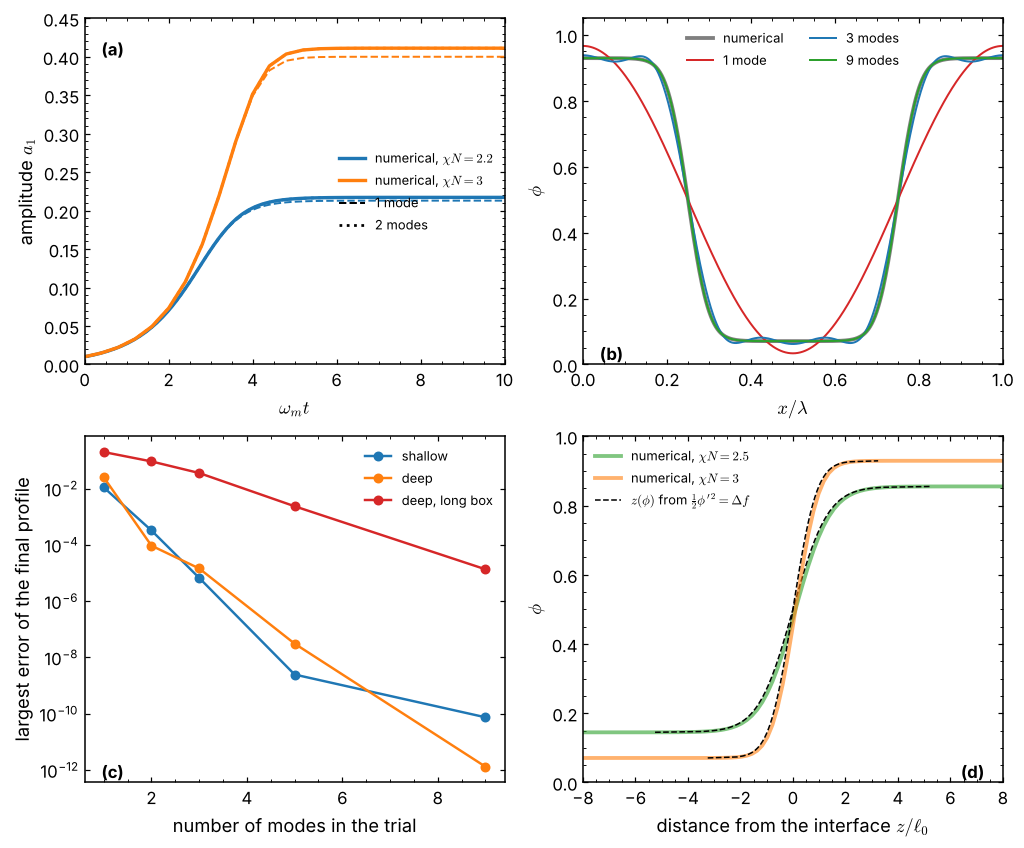

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
ax = axes[0, 0]
for name, color in (("shallow", "C0"), ("deep", "C1")):
    chi, q, times, xg, numerical, a1_num, runs = results[name]
    ax.plot(times * d2f(0.5, chi) ** 2 / 4, a1_num, color=color, lw=2.2, label=rf"numerical, $\chi N = {chi:g}$")
    ax.plot(times * d2f(0.5, chi) ** 2 / 4, runs[1][0][:, 0], "--", color=color, lw=1.3)
    ax.plot(times * d2f(0.5, chi) ** 2 / 4, runs[2][0][:, 0], ":", color=color, lw=1.8)
ax.plot([], [], "k--", lw=1.3, label="1 mode"); ax.plot([], [], "k:", lw=1.8, label="2 modes")
ax.set_xlabel(r"$\omega_mt$"); ax.set_ylabel(r"amplitude $a_1$"); ax.set_xlim(0, 10); ax.set_ylim(0, 0.45)
ax.legend(loc="center right", fontsize=8.5); on.panel_label(ax, "(a)", x=0.04, y=0.94)

ax = axes[0, 1]
chi, q, times, xg, numerical, a1_num, runs = results["deep, long box"]
ax.plot(xg * q / (2 * np.pi), numerical[-1], "k", lw=2.5, alpha=0.5, label="numerical")
for n_modes, color in zip((1, 3, 9), ("C3", "C0", "C2")):
    ax.plot(xg * q / (2 * np.pi), runs[n_modes][1][-1], color=color, lw=1.3, label=f"{n_modes} mode" + ("s" if n_modes > 1 else ""))
ax.set_xlabel(r"$x/\lambda$"); ax.set_ylabel(r"$\phi$"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
ax.legend(loc="upper center", fontsize=8.5, ncol=2); on.panel_label(ax, "(b)", x=0.04, y=0.06)

ax = axes[1, 0]
for (name, color) in (("shallow", "C0"), ("deep", "C1"), ("deep, long box", "C3")):
    chi, q, times, xg, numerical, a1_num, runs = results[name]
    ns = sorted(runs)
    ax.semilogy(ns, [np.max(np.abs(runs[n][1][-1] - numerical[-1])) for n in ns], "o-", color=color, label=name)
ax.set_xlabel("number of modes in the trial"); ax.set_ylabel("largest error of the final profile")
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(c)", x=0.04, y=0.06)

ax = axes[1, 1]
for chi, color in zip((2.5, 3.0), ("C2", "C1")):
    pe, gamma, xx, relaxed = tension[chi]
    ax.plot(xx - 50, relaxed, color=color, lw=2.5, alpha=0.6, label=rf"numerical, $\chi N = {chi:g}$")
    ps = np.linspace(pe + 1e-4, 1 - pe - 1e-4, 300)
    zs = np.array([quad(lambda p: 1 / math.sqrt(max(2 * (f(p, chi) - f(pe, chi)), 1e-300)), 0.5, s)[0] for s in ps])
    ax.plot(zs, ps, "k--", lw=1)
ax.plot([], [], "k--", lw=1, label=r"$z(\phi)$ from $\frac{1}{2}\phi'^2 = \Delta f$")
ax.set_xlabel(r"distance from the interface $z/\ell_0$"); ax.set_ylabel(r"$\phi$"); ax.set_xlim(-8, 8); ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(d)", x=0.9, y=0.06)
plt.show()

**Figure 12.2.** **(a)** Growth and saturation of the first Fourier mode in a box of the
fastest wavelength: numerical solution (full lines) and trials with one mode (dashed)
and two modes (dotted). **(b)** Final profile in a long box, $\chi N = 3$: numerical and
trials with 1, 3 and 9 modes. **(c)** Convergence of the trials. **(d)** The interface:
numerical profiles and the exact profile from $\tfrac12\phi'^2 = \Delta f$.

The trial behaves as the earlier chapters taught us to expect.

* *A smooth pattern needs few modes.* In a box of the fastest wavelength the
  saturated profile is nearly sinusoidal. One mode gives the final amplitude within
  2 % for the shallow quench and 3 % for the deep one, and follows the whole growth
  curve; two modes bring the error of the profile down to $3\times10^{-4}$ or less. The one-mode trial is the simplest
  nonlinear theory of spinodal decomposition: it shows where the exponential growth
  must stop.
* *Sharp interfaces need many.* In the long box the deep quench forms two flat
  phases separated by two interfaces, much narrower than the box. One mode puts a
  sine wave where there should be a square one (error 0.2), and the error falls slowly
  with the number of modes: nine are needed to reach $10^{-5}$. The trial converges, as a
  spectral method must, but it has to build the interfaces out of harmonics.
* *The interface is right.* The relaxed interfaces of the numerical solution lie on
  the exact profile, and their excess free energy agrees with the tension (12.8) to
  six digits.

The lesson is the one of Chapters 5 and 10: a trial family is good when its members
look like the solution. For a pattern with sharp interfaces the natural slow
variables are the positions of the interfaces, not Fourier amplitudes; that is the
starting point of the coarsening argument below.

## 12.5 Coarsening

After the pattern has saturated, the interfaces carry an excess free energy $\gamma$ per
unit area, and the system lowers it by coarsening. A scaling argument with the two
functions gives the rate. Let $\ell(t)$ be the size of the domains. The interfacial
area per unit volume is of order $1/\ell$, so the free energy per unit volume is

$$ A \simeq c_1\,\frac{\gamma}{\ell} . $$

When the domains grow by $d\ell$, a fraction $d\ell/\ell$ of the material, of composition
difference $\Delta\phi = 1 - 2\phi_e$, is carried a distance of order $\ell$. The flux is therefore
of order $\Delta\phi\,\dot\ell$, and the dissipation per unit volume is $\Phi \simeq c_2\,(\Delta\phi\,\dot\ell)^2/2\Lambda$.
Minimising $R = \Phi + \dot A$ over $\dot\ell$,

$$ c_2\,\frac{\Delta\phi^2}{\Lambda}\,\dot\ell = c_1\,\frac{\gamma}{\ell^2} \quad\Longrightarrow\quad \ell^3 \simeq \frac{3c_1}{c_2}\,\frac{\Lambda\gamma}{\Delta\phi^2}\;t . \tag{12.13} $$

This is the law of Lifshitz and Slyozov (1961), derived by them for the ripening
of droplets. The argument fixes the exponent, not the number $c_1/c_2$. The cell
below follows a two-dimensional mixture after a quench to $\chi N = 2.5$ and measures the
domain size from the structure factor, $\ell = 2\pi/\langle q\rangle$, and the excess free energy.

In [8]:
chi, n, box, dt = 2.5, 256, 256.0, 0.5
t_2d = np.array([0, 12.5, 25, 50, 100, 200, 400, 800, 1600, 3200, 6400])
rng = np.random.default_rng(1)
snaps = on.cahn_hilliard_spectral(0.5 + 0.01 * rng.standard_normal((n, n)), box, t_2d, lambda p: df(p, chi), dt)
k = 2 * np.pi * np.fft.fftfreq(n, d=box / n)
kx, ky = np.meshgrid(k, k, indexing="ij")
kk = np.sqrt(kx**2 + ky**2)

def domain_size(p):
    s = np.abs(np.fft.fft2(p - p.mean())) ** 2
    return 2 * np.pi * s.sum() / (s * kk).sum()

def excess_energy(p):
    h = np.fft.fft2(p)
    gx, gy = np.real(np.fft.ifft2(1j * kx * h)), np.real(np.fft.ifft2(1j * ky * h))
    pe = binodal(chi)
    return np.mean(f(np.clip(p, 1e-12, 1 - 1e-12), chi) - f(pe, chi) + 0.5 * (gx**2 + gy**2))

sizes = np.array([domain_size(p) for p in snaps[1:]])
excess = np.array([excess_energy(p) for p in snaps[1:]])
gamma = tension[2.5][1]
local = np.diff(np.log(sizes)) / np.diff(np.log(t_2d[1:]))
print("     t      domain size   local exponent   excess energy x size / gamma")
for i, t in enumerate(t_2d[1:]):
    exponent = f"{local[i - 1]:.3f}" if i > 0 else "  -  "
    print(f"  {t:7.1f}     {sizes[i]:7.2f}        {exponent}           {excess[i] * sizes[i] / gamma:.3f}")
print(f"mean composition conserved to {np.ptp(snaps.mean(axis=(1, 2))):.1e}")

     t      domain size   local exponent   excess energy x size / gamma
     12.5        9.14          -             2.501
     25.0        9.24        0.015           2.116
     50.0       10.75        0.219           2.052
    100.0       13.11        0.285           2.008
    200.0       16.01        0.288           1.940
    400.0       18.94        0.243           1.869
    800.0       22.81        0.268           1.789
   1600.0       27.29        0.259           1.704
   3200.0       33.17        0.281           1.613
   6400.0       40.45        0.286           1.520
mean composition conserved to 1.1e-16


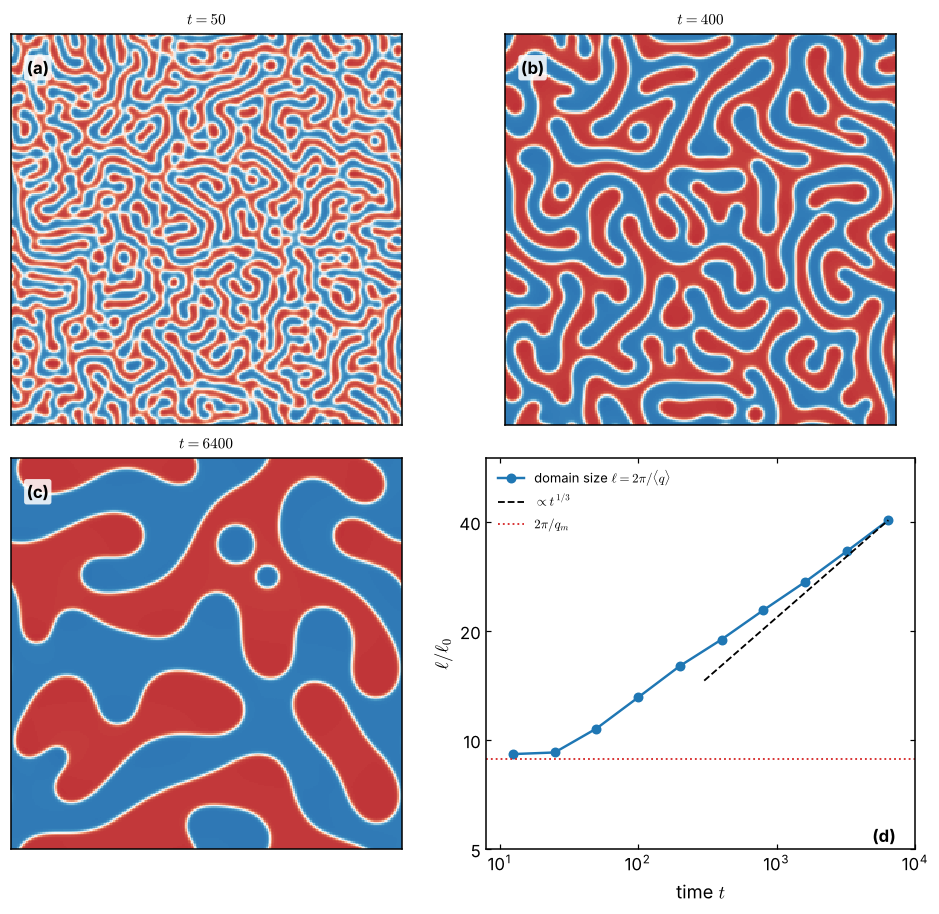

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(8.6, 8.2))
for ax, i, label in zip(axes.flat[:3], (3, 6, 10), ("(a)", "(b)", "(c)")):
    ax.imshow(snaps[i].T, origin="lower", cmap="RdBu_r", vmin=0, vmax=1, extent=(0, box, 0, box), interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(rf"$t = {t_2d[i]:g}$", fontsize=10)
    ax.text(0.04, 0.94, label, transform=ax.transAxes, fontsize=11, fontweight="bold", va="top",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax = axes[1, 1]
ax.loglog(t_2d[1:], sizes, "C0o-", label=r"domain size $\ell = 2\pi/\langle q\rangle$")
tt = np.array([300, 6400])
ax.loglog(tt, sizes[-1] * (tt / tt[-1]) ** (1 / 3), "k--", lw=1.2, label=r"$\propto t^{1/3}$")
ax.axhline(2 * np.pi / math.sqrt(-d2f(0.5, chi) / 2), color="C3", ls=":", lw=1.2, label=r"$2\pi/q_m$")
ax.set_xlabel(r"time $t$"); ax.set_ylabel(r"$\ell/\ell_0$"); ax.set_xlim(8, 1e4); ax.set_ylim(5, 60)
ax.set_yticks([5, 10, 20, 40], ["5", "10", "20", "40"]); ax.minorticks_off()
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(d)", x=0.9, y=0.06)
plt.show()

**Figure 12.3.** Spinodal decomposition and coarsening in two dimensions, $\chi N = 2.5$,
$\bar\phi = \tfrac12$. **(a)–(c)** The composition at three times (red: rich in A, blue: rich in B).
**(d)** The domain size against time.

The pattern first appears at the fastest wavelength $2\pi/q_m$ of the linear theory
(panel a, dotted line in d), then coarsens. Over two decades of time the domain
size grows with a local exponent between 0.24 and 0.29, a little below the $1/3$ of
Eq. (12.13). This is the usual finding in simulations: Huse (1986) showed that
transport along the interfaces adds corrections of relative order $1/\ell$, which make
the approach to $1/3$ slow.

The scaling argument assumed $A \simeq c_1\gamma/\ell$ with a constant $c_1$. The product of the
excess free energy and the domain size, divided by $\gamma$, is $c_1$; it falls from 2.0 to 1.5
while $\ell$ grows threefold. The pattern is therefore not yet exactly self-similar,
another sign that the asymptotic regime has not been reached in a box of this size.
The mean composition is conserved to rounding error, and the free energy falls
monotonically (`tests/test_onsager.py`).

## 12.6 What to trust

* The Cahn–Hilliard equation is a mean-field theory: it leaves out thermal
  fluctuations, which matter near the critical point and decide the first stage of a
  shallow quench. For polymer blends with large $N$ the mean field is accurate
  except very close to the critical point.
* The gradient coefficient and the mobility were taken constant. For polymer
  blends both depend on composition (de Gennes, 1980); the structure of the
  equation and the method are unchanged.
* There is no flow. In a liquid mixture the interfacial tension drives a flow that
  carries the domains, and coarsening becomes faster than $t^{1/3}$ once the domains are
  large; that needs the velocity of the mixture as an additional slow variable, with
  the viscous dissipation of Chapter 4.

## Summary

* The free energy of a nonuniform mixture is the free energy of mixing plus a
  gradient term; the dissipation is the friction of interdiffusion. Minimising the
  Rayleighian gives the Cahn–Hilliard equation.
* Inside the spinodal, fluctuations grow at the rate $-\Lambda q^2(f'' + \kappa q^2)$, fastest at
  $q_m = (-f''/2\kappa)^{1/2}$. The interfacial tension follows from the free energy alone.
* A trial with one Fourier mode contains the linear theory and gives the saturated
  amplitude of the pattern within a few per cent; a pattern with sharp interfaces
  needs many modes.
* Domains coarsen as $\ell \propto t^{1/3}$, a law that follows from the same two functions by a
  scaling argument; in simulations the exponent is approached slowly.

## Exercises

Sample solutions are in [`solutions/part3_soft_materials/12_solutions.ipynb`](../../solutions/part3_soft_materials/12_solutions.ipynb).

1. **Near the critical point.** Expand the Flory–Huggins free energy about $\phi = \tfrac12$ to
   fourth order in $\psi = \phi - \tfrac12$. Show that the binodal is $\psi_e^2 \approx \tfrac38(\chi N - 2)$, that the
   interface is $\psi = \psi_e\tanh(z/w)$ with $w = (\chi N - 2)^{-1/2}$ (in units of $\ell_0$), and that the
   tension is $\gamma \approx \tfrac12(\chi N - 2)^{3/2}$, the exponent found by Cahn and Hilliard (1958).
   Compare with the exact values of Eqs. (12.7) and (12.8) for $\chi N$ from 2.01 to 3.
2. **The one-mode trial in closed form.** With the quartic free energy of Exercise 1,
   evaluate Eq. (12.12) for one mode analytically and find the saturated amplitude
   as a function of $q$ and $\chi N$. For which $q$ is it largest? Compare with the
   numerical result for $\chi N = 2.2$.
3. **An off-critical quench.** Repeat the linear analysis for $\bar\phi = 0.3$ at $\chi N = 3$. Is
   the mixture inside the spinodal? Run a two-dimensional simulation and describe
   the pattern. What changes in the coarsening argument when one phase forms
   droplets in the other?
4. **Polymer blends.** For a polymer blend, de Gennes (1980) wrote the gradient term
   as $(k_BT/v)\,b^2(\nabla\phi)^2/36\phi(1 - \phi)$, with $b$ the segment length; in the notation of
   Eq. (12.1) this is $\kappa = k_BT\,b^2/18v\phi(1 - \phi)$. For $N = 1000$, $b = 0.7$ nm and $\phi = \tfrac12$, find
   $\ell_0$ and the fastest wavelength $2\pi/q_m$ after quenches to $\chi N = 2.5$ and $2.05$. Compare with a
   mixture of small molecules ($N = 1$). Why can light scattering follow the spinodal
   decomposition of polymer blends?

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* J. W. Cahn and J. E. Hilliard, "Free energy of a nonuniform system. I. Interfacial free energy", *J. Chem. Phys.* **28**, 258 (1958).
* J. W. Cahn, "On spinodal decomposition", *Acta Metall.* **9**, 795 (1961).
* J. W. Cahn, "Phase separation by spinodal decomposition in isotropic systems", *J. Chem. Phys.* **42**, 93 (1965).
* I. M. Lifshitz and V. V. Slyozov, "The kinetics of precipitation from supersaturated solid solutions", *J. Phys. Chem. Solids* **19**, 35 (1961).
* P. G. de Gennes, "Dynamics of fluctuations and spinodal decomposition in polymer blends", *J. Chem. Phys.* **72**, 4756 (1980).
* D. A. Huse, "Corrections to late-stage behavior in spinodal decomposition: Lifshitz–Slyozov scaling and Monte Carlo simulations", *Phys. Rev. B* **34**, 7845 (1986).

---

**Previous:** [11. Swelling and squeezing of a gel](11_gel_swelling.ipynb) &nbsp;·&nbsp; **Next:** [13. Polymer dynamics](13_polymer_dynamics.ipynb)